In [1]:
import torch
from torch import nn
import transformers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
print(torch.__version__)
print(transformers.__version__)

2.0.1+cu117
4.27.1


In [3]:
import matplotlib as mpl
# default: 100
mpl.rcParams['figure.dpi'] = 200

## text classification
- 也叫 sequence classification
- sentiment analysis
  - 情感分析，就是一种文本/序列分类
  - 电商评论
    - social web：weibo/tweet

In [4]:
from datasets import load_dataset

In [5]:
emotions = load_dataset('emotion')

Using the latest cached version of the module from /root/.cache/huggingface/modules/datasets_modules/datasets/emotion/cca5efe2dfeb58c1d098e0f9eeb200e9927d889b5a03c67097275dfb5fe463bd (last modified on Mon May 29 14:10:26 2023) since it couldn't be found locally at emotion., or remotely on the Hugging Face Hub.
No config specified, defaulting to: emotion/split
Found cached dataset emotion (/root/.cache/huggingface/datasets/emotion/split/1.0.0/cca5efe2dfeb58c1d098e0f9eeb200e9927d889b5a03c67097275dfb5fe463bd)


  0%|          | 0/3 [00:00<?, ?it/s]

In [6]:
emotions

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

In [7]:
print(emotions["train"][:5])
print(emotions["train"]['text'][:5])
print(emotions["train"]['label'][:5])

{'text': ['i didnt feel humiliated', 'i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake', 'im grabbing a minute to post i feel greedy wrong', 'i am ever feeling nostalgic about the fireplace i will know that it is still on the property', 'i am feeling grouchy'], 'label': [0, 0, 3, 2, 3]}
['i didnt feel humiliated', 'i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake', 'im grabbing a minute to post i feel greedy wrong', 'i am ever feeling nostalgic about the fireplace i will know that it is still on the property', 'i am feeling grouchy']
[0, 0, 3, 2, 3]


In [8]:
print(emotions["train"].features)
print(emotions["train"].features['label'])
print(emotions["train"].features['label'].int2str(2))

{'text': Value(dtype='string', id=None), 'label': ClassLabel(names=['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'], id=None)}
ClassLabel(names=['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'], id=None)
love


## data visualization analysis
- dataset => dataframe
- text length
- label freq

### dataset to dataframe

In [9]:
emotions_df = pd.DataFrame.from_dict(emotions['train'])

In [10]:
emotions_df

,text,label
0,i didnt feel humiliated,0
1,i can go from feeling so hopeless to so damned...,0
2,im grabbing a minute to post i feel greedy wrong,3
3,i am ever feeling nostalgic about the fireplac...,2
4,i am feeling grouchy,3
...,...,...
15995,i just had a very brief time in the beanbag an...,0
15996,i am now turning and i feel pathetic that i am...,0
15997,i feel strong and good overall,1
15998,i feel like this was such a rude comment and i...,3


In [11]:
emotions_df['label_name'] = emotions_df['label'].apply(lambda x: emotions["train"].features['label'].int2str(x))

In [12]:
emotions_df

,text,label,label_name
0,i didnt feel humiliated,0,sadness
1,i can go from feeling so hopeless to so damned...,0,sadness
2,im grabbing a minute to post i feel greedy wrong,3,anger
3,i am ever feeling nostalgic about the fireplac...,2,love
4,i am feeling grouchy,3,anger
...,...,...,...
15995,i just had a very brief time in the beanbag an...,0,sadness
15996,i am now turning and i feel pathetic that i am...,0,sadness
15997,i feel strong and good overall,1,joy
15998,i feel like this was such a rude comment and i...,3,anger


## label analysis

In [13]:
emotions_df.label.value_counts()

1    5362
0    4666
3    2159
4    1937
2    1304
5     572
Name: label, dtype: int64

In [14]:
emotions_df.label_name.value_counts()

joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: label_name, dtype: int64

Text(0.5, 1.0, 'freq of labels')

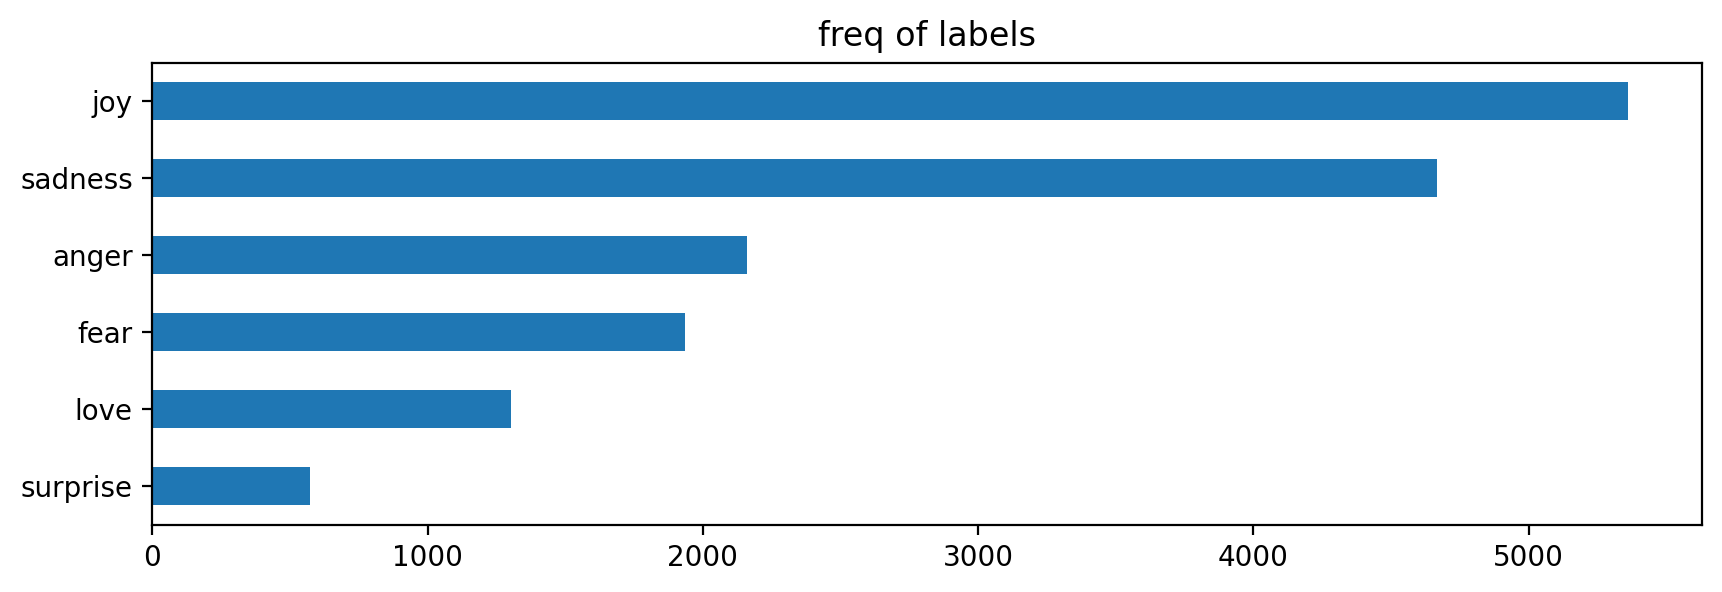

In [15]:
plt.figure(figsize=(10, 3))
emotions_df['label_name'].value_counts(ascending=True).plot.barh()
plt.title('freq of labels')

### text length analysis


Text(0.5, 0, '')

<Figure size 800x400 with 0 Axes>

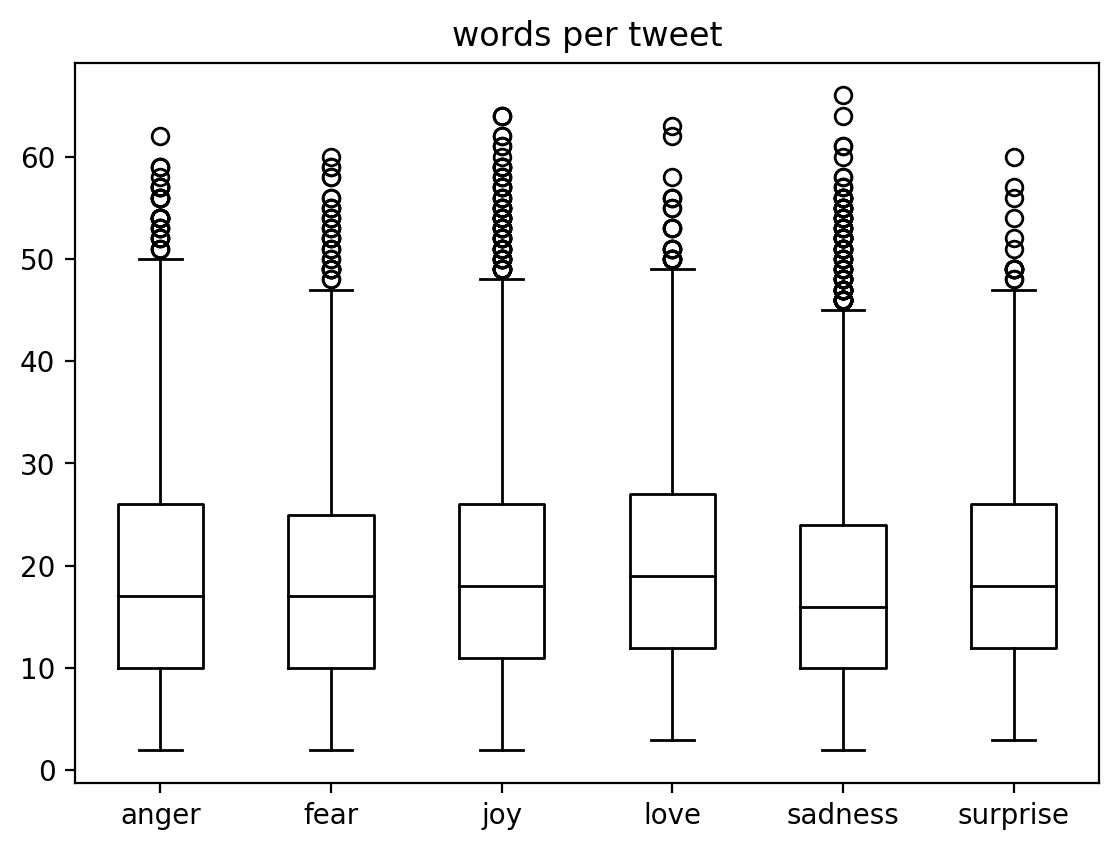

In [16]:
plt.figure(figsize=(4, 2))
emotions_df['words per tweet'] = emotions_df['text'].str.split().apply(len)
emotions_df.boxplot('words per tweet', by='label_name', 
#                     showfliers=False, 
                    grid=False, 
                    color='black')
plt.suptitle('')
plt.xlabel('')

## text => tokens
数据集转换为模型接受的输入类型

- Subword Tokenization
  - WordPiece
    - BERT and DistilBERT
- hugging face:
  - ~/.cache/huggingface/
- tokenizer
  - tokenizer.vocab_size
  - model config
    - tokenizer.model_max_length
    - tokenizer.model_input_names

### tokenizer

In [17]:
from transformers import AutoTokenizer

In [18]:
model_ckpt = 'distilbert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(model_ckpt)

In [19]:
print(tokenizer.encode("hello world"))
print(tokenizer.encode("heLlo WorlD"))

[101, 7592, 2088, 102]
[101, 7592, 2088, 102]


## tokenize the whole dataset

In [20]:
def batch_tokenize(batch):
    return tokenizer(batch['text'], padding=True, truncation=True)

In [21]:
emotions_encoded = emotions.map(batch_tokenize, batched=True, batch_size=None)

Loading cached processed dataset at /root/.cache/huggingface/datasets/emotion/split/1.0.0/cca5efe2dfeb58c1d098e0f9eeb200e9927d889b5a03c67097275dfb5fe463bd/cache-c6b08da13a34a829.arrow


Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Loading cached processed dataset at /root/.cache/huggingface/datasets/emotion/split/1.0.0/cca5efe2dfeb58c1d098e0f9eeb200e9927d889b5a03c67097275dfb5fe463bd/cache-1d06b894104271d3.arrow


In [22]:
emotions_encoded

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 2000
    })
})

In [33]:
labels = emotions['train'].features['label'].names
print(labels)
# 下游任务（downstream task）
num_classes = len(labels)

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']


In [24]:
# list to tensor
emotions_encoded.set_format('torch', columns=['label', 'input_ids', 'attention_mask'])
type(emotions_encoded['train']['input_ids'])

torch.Tensor

## fine-tune transformers
### distilbert-base-uncased
- distilbert 是对 bert 的 distill 而来
  - 模型结构更为简单，
  - bert-base-uncased 参数量：109482240
  - distilbert-base-uncased 参数量：66362880

In [34]:
from transformers import AutoModelForSequenceClassification
model_ckpt = 'distilbert-base-uncased'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# model = AutoModelForSequenceClassification.from_pretrained(model_ckpt)
model = AutoModelForSequenceClassification.from_pretrained(model_ckpt, num_labels=num_classes).to(device)
model

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): MultiHeadSelfAttention(
            (dropout): Dropout(p=0.1, inplace=False)
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)
 

## trainer

In [35]:
# https://huggingface.co/settings/tokens
# (write)
from huggingface_hub import notebook_login
notebook_login()

In [36]:
# https://huggingface.co/docs/transformers/main_classes/trainer
# https://huggingface.co/docs/transformers/v4.28.1/en/main_classes/trainer#transformers.TrainingArguments
from transformers import TrainingArguments, Trainer

In [37]:
batch_size = 64
logging_steps = len(emotions_encoded['train']) // batch_size
model_name = f'{model_ckpt}_emotion_ft_0529'
training_args = TrainingArguments(output_dir=model_name, 
                                  num_train_epochs=4, 
                                  learning_rate=2e-5,
                                  weight_decay=0.01,
                                  per_device_train_batch_size=batch_size,
                                  per_device_eval_batch_size=batch_size,
                                  evaluation_strategy="epoch",
                                  disable_tqdm=False,
                                  logging_steps=logging_steps,
                                  # write
                                  push_to_hub=True, 
                                  log_level="error")

## trainer默认自动开启 torch 的多gpu模式，
- per_device_train_batch_size: 这里是设置每个gpu上的样本数量，
  - 一般来说，多gpu模式希望多个gpu的性能尽量接近，否则最终多gpu的速度由最慢的gpu决定，
    - 比如快gpu 跑一个batch需要5秒，跑10个batch 50秒，慢的gpu跑一个batch 500秒，则快gpu还要等慢gpu跑完一个batch然后一起更新weights，速度反而更慢了。
  - 同理 per_device_eval_batch_size 类似
- learning_rate/weight_decay
  - 默认使用AdamW的优化算法

In [38]:
from transformers_utils import compute_classification_metrics
trainer = Trainer(model=model, 
                  tokenizer=tokenizer,
                  train_dataset=emotions_encoded['train'],
                  eval_dataset=emotions_encoded['validation'],
                  args=training_args, 
                  compute_metrics=compute_classification_metrics)

Cloning https://huggingface.co/rzhu/distilbert-base-uncased_emotion_ft_0529 into local empty directory.


In [39]:
trainer.train()

/root/miniconda3/envs/DL/lib/python3.10/site-packages/transformers/optimization.py:391: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision
1,0.810900,0.268565,0.913000,0.911143,0.895809
2,0.207800,0.166321,0.931000,0.930903,0.914831
3,0.138300,0.156247,0.936500,0.936563,0.916971
4,0.114000,0.148510,0.937500,0.937813,0.912403


TrainOutput(global_step=1000, training_loss=0.31774823188781737, metrics={'train_runtime': 56.4541, 'train_samples_per_second': 1133.663, 'train_steps_per_second': 17.713, 'total_flos': 1440685723392000.0, 'train_loss': 0.31774823188781737, 'epoch': 4.0})

In [40]:
emotions_encoded["validation"]

Dataset({
    features: ['text', 'label', 'input_ids', 'attention_mask'],
    num_rows: 2000
})

In [47]:
preds_output = trainer.predict(emotions_encoded["validation"])

In [48]:
preds_output

PredictionOutput(predictions=array([[ 5.463056  , -1.0693368 , -1.3837177 , -1.5474973 , -1.8014793 ,
        -1.6768212 ],
       [ 5.508445  , -1.2748182 , -1.9435219 , -1.4962589 , -1.0395306 ,
        -1.694908  ],
       [-1.3338864 ,  2.807299  ,  3.7083807 , -1.3195832 , -2.1905422 ,
        -1.870305  ],
       ...,
       [-1.1935714 ,  5.936615  , -0.35125533, -1.4357302 , -2.0184283 ,
        -1.1012882 ],
       [-1.6146266 ,  3.7243018 ,  3.2317545 , -1.6552223 , -2.299628  ,
        -1.6577642 ],
       [-1.2071064 ,  5.8223367 , -0.3029895 , -1.6559126 , -2.0616121 ,
        -0.7823803 ]], dtype=float32), label_ids=array([0, 0, 2, ..., 1, 1, 1]), metrics={'test_loss': 0.14850957691669464, 'test_accuracy': 0.9375, 'test_f1': 0.9378132226886893, 'test_precision': 0.9124034390576776, 'test_runtime': 0.4686, 'test_samples_per_second': 4268.327, 'test_steps_per_second': 68.293})

In [50]:
y_preds = preds_output.predictions.argmax(-1)
y_preds

array([0, 0, 2, ..., 1, 1, 1])

In [51]:
y_true = emotions_encoded['validation']['label']

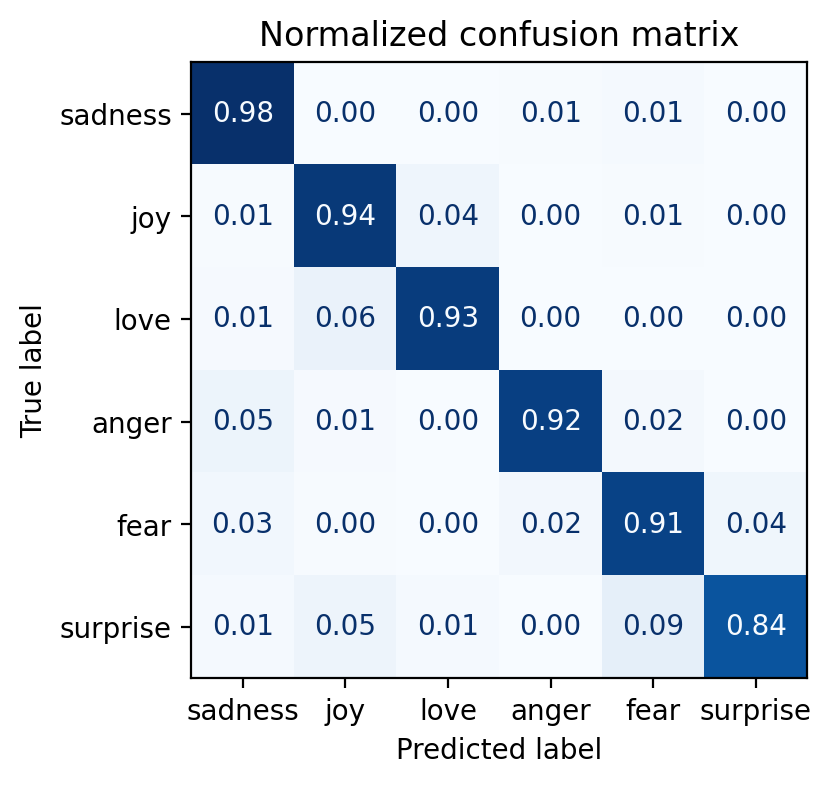

In [52]:
from transformers_utils import plot_confusion_matrix
plot_confusion_matrix(y_preds, y_true, labels)

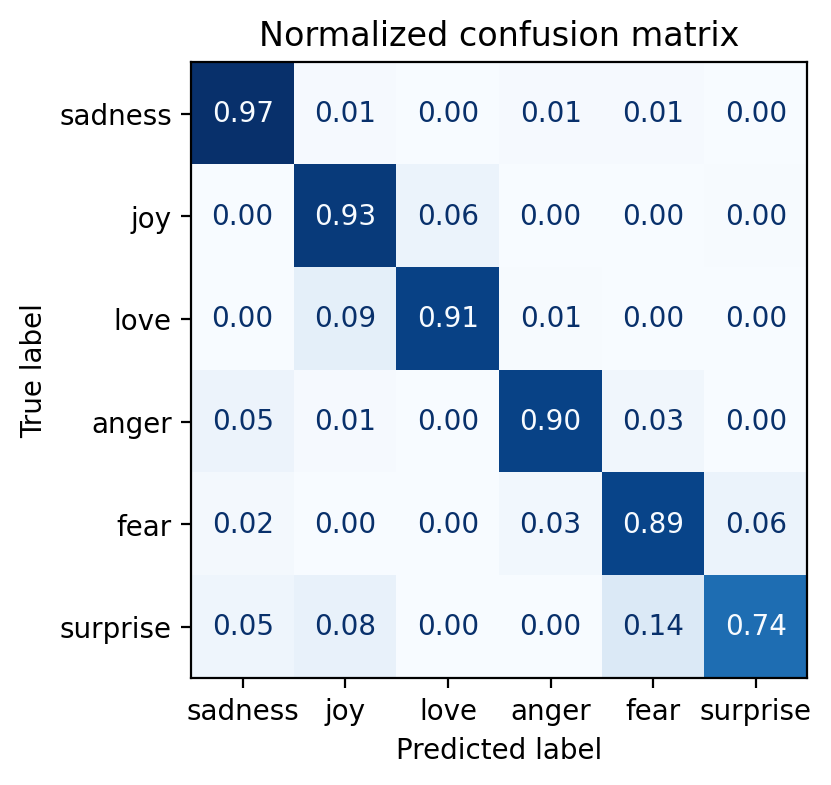

In [53]:
# 验证数据集

preds_output = trainer.predict(emotions_encoded["test"])
y_preds = np.argmax(preds_output.predictions, axis=-1)
y_true = emotions_encoded["test"]['label']
plot_confusion_matrix(y_preds, y_true, labels)

## result analysis

In [54]:
from torch.nn.functional import cross_entropy

In [55]:
def forward_pass_with_label(batch):
    # Place all input tensors on the same device as the model
    inputs = {k:v.to(device) for k,v in batch.items() 
              if k in tokenizer.model_input_names}

    with torch.no_grad():
        output = model(**inputs)
        pred_label = torch.argmax(output.logits, axis=-1)
        loss = cross_entropy(output.logits, batch["label"].to(device), 
                             reduction="none")

    # Place outputs on CPU for compatibility with other dataset columns   
    return {"loss": loss.cpu().numpy(), 
            "predicted_label": pred_label.cpu().numpy()}

In [56]:
emotions_encoded["validation"] = emotions_encoded["validation"].map(
    forward_pass_with_label, batched=True, batch_size=16)

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [57]:
emotions_encoded['validation']

Dataset({
    features: ['text', 'label', 'input_ids', 'attention_mask', 'loss', 'predicted_label'],
    num_rows: 2000
})

In [58]:
selected_cols = ['text', 'label', 'predicted_label', 'loss']

In [59]:
valid_df = pd.DataFrame.from_dict({'text': emotions_encoded["validation"]['text'], 
                                   'label': emotions_encoded['validation']['label'].numpy(), 
                                   'pred_label': emotions_encoded['validation']['predicted_label'].numpy(), 
                                   'loss': emotions_encoded["validation"]['loss'].numpy()})
valid_df['label'] = valid_df['label'].apply(lambda x: labels[x])
valid_df['pred_label'] = valid_df['pred_label'].apply(lambda x: labels[x])

In [60]:
valid_df

,text,label,pred_label,loss
0,im feeling quite sad and sorry for myself but ...,sadness,sadness,0.004901
1,i feel like i am still looking at a blank canv...,sadness,sadness,0.004786
2,i feel like a faithful servant,love,love,0.354636
3,i am just feeling cranky and blue,anger,anger,0.009578
4,i can have for a treat or if i am feeling festive,joy,joy,0.004417
...,...,...,...,...
1995,im having ssa examination tomorrow in the morn...,sadness,sadness,0.005334
1996,i constantly worry about their fight against n...,joy,joy,0.005264
1997,i feel its important to share this info for th...,joy,joy,0.004506
1998,i truly feel that if you are passionate enough...,joy,joy,0.487043


In [61]:
valid_df[valid_df['label'] != valid_df['pred_label']]

,text,label,pred_label,loss
17,i know what it feels like he stressed glaring ...,anger,sadness,2.228074
27,i feel as if i am the beloved preparing hersel...,joy,love,1.302825
35,i am feeling very blessed today that they shar...,joy,love,1.094969
55,i didn t feel accepted,joy,love,0.874549
91,i feel like the people i know are really gener...,joy,love,1.367633
...,...,...,...,...
1958,i so desperately want to be able to help but i...,fear,sadness,1.216845
1963,i called myself pro life and voted for perry w...,joy,sadness,6.266733
1964,i feel vaguely cheated and a little amused,joy,anger,2.134216
1981,i spent a lot of time feeling overwhelmed with...,fear,surprise,1.096283


In [62]:
1-125/2000

0.9375

In [63]:
valid_df[valid_df['label'] != valid_df['pred_label']].label.value_counts()

joy         43
anger       23
fear        20
love        13
sadness     13
surprise    13
Name: label, dtype: int64

In [64]:
valid_df.sort_values('loss', ascending=False).head(10)

,text,label,pred_label,loss
1950,i as representative of everything thats wrong ...,surprise,sadness,6.440859
1963,i called myself pro life and voted for perry w...,joy,sadness,6.266733
1500,i guess we would naturally feel a sense of lon...,anger,sadness,6.045938
405,i have been feeling extraordinarily indecisive...,fear,joy,5.602048
1870,i guess i feel betrayed because i admired him ...,joy,sadness,5.141024
1111,im lazy my characters fall into categories of ...,joy,fear,5.128436
1840,id let you kill it now but as a matter of fact...,joy,fear,5.018057
318,i felt ashamed of these feelings and was scare...,fear,sadness,4.756170
1683,i had applied for a job and they had assured m...,anger,joy,4.680286
1836,i got a very nasty electrical shock when i was...,fear,anger,4.615105


In [65]:
valid_df.iloc[1950].text

'i as representative of everything thats wrong with corporate america and feel that sending him to washington is a ludicrous idea'

In [67]:
valid_df.sort_values('loss', ascending=False).head(20)

,text,label,pred_label,loss
1950,i as representative of everything thats wrong ...,surprise,sadness,6.440859
1963,i called myself pro life and voted for perry w...,joy,sadness,6.266733
1500,i guess we would naturally feel a sense of lon...,anger,sadness,6.045938
405,i have been feeling extraordinarily indecisive...,fear,joy,5.602048
1870,i guess i feel betrayed because i admired him ...,joy,sadness,5.141024
1111,im lazy my characters fall into categories of ...,joy,fear,5.128436
1840,id let you kill it now but as a matter of fact...,joy,fear,5.018057
318,i felt ashamed of these feelings and was scare...,fear,sadness,4.756170
1683,i had applied for a job and they had assured m...,anger,joy,4.680286
1836,i got a very nasty electrical shock when i was...,fear,anger,4.615105


## to huggingface hub

In [68]:
trainer.push_to_hub(commit_message="Training completed!")

Upload file pytorch_model.bin:   0%|          | 1.00/255M [00:00<?, ?B/s]

To https://huggingface.co/rzhu/distilbert-base-uncased_emotion_ft_0529
   83b7241..5490e40  main -> main

To https://huggingface.co/rzhu/distilbert-base-uncased_emotion_ft_0529
   5490e40..13b2657  main -> main



'https://huggingface.co/rzhu/distilbert-base-uncased_emotion_ft_0529/commit/5490e402e547e421ab511a6da95af64050095aa5'

In [69]:
#hide_output
from transformers import pipeline

# Change `transformersbook` to your Hub username
model_id = "rzhu/distilbert-base-uncased_emotion_ft_0529"
classifier = pipeline("text-classification", model=model_id)

In [70]:
custom_tweet = "I saw a movie today and it suck."
preds = classifier(custom_tweet, return_all_scores=True)
preds

/root/miniconda3/envs/DL/lib/python3.10/site-packages/transformers/pipelines/text_classification.py:104: UserWarning: `return_all_scores` is now deprecated,  if want a similar funcionality use `top_k=None` instead of `return_all_scores=True` or `top_k=1` instead of `return_all_scores=False`.
  warnings.warn(


[[{'label': 'LABEL_0', 'score': 0.19341139495372772},
  {'label': 'LABEL_1', 'score': 0.15241628885269165},
  {'label': 'LABEL_2', 'score': 0.00846957042813301},
  {'label': 'LABEL_3', 'score': 0.543761134147644},
  {'label': 'LABEL_4', 'score': 0.08774767071008682},
  {'label': 'LABEL_5', 'score': 0.014193982817232609}]]

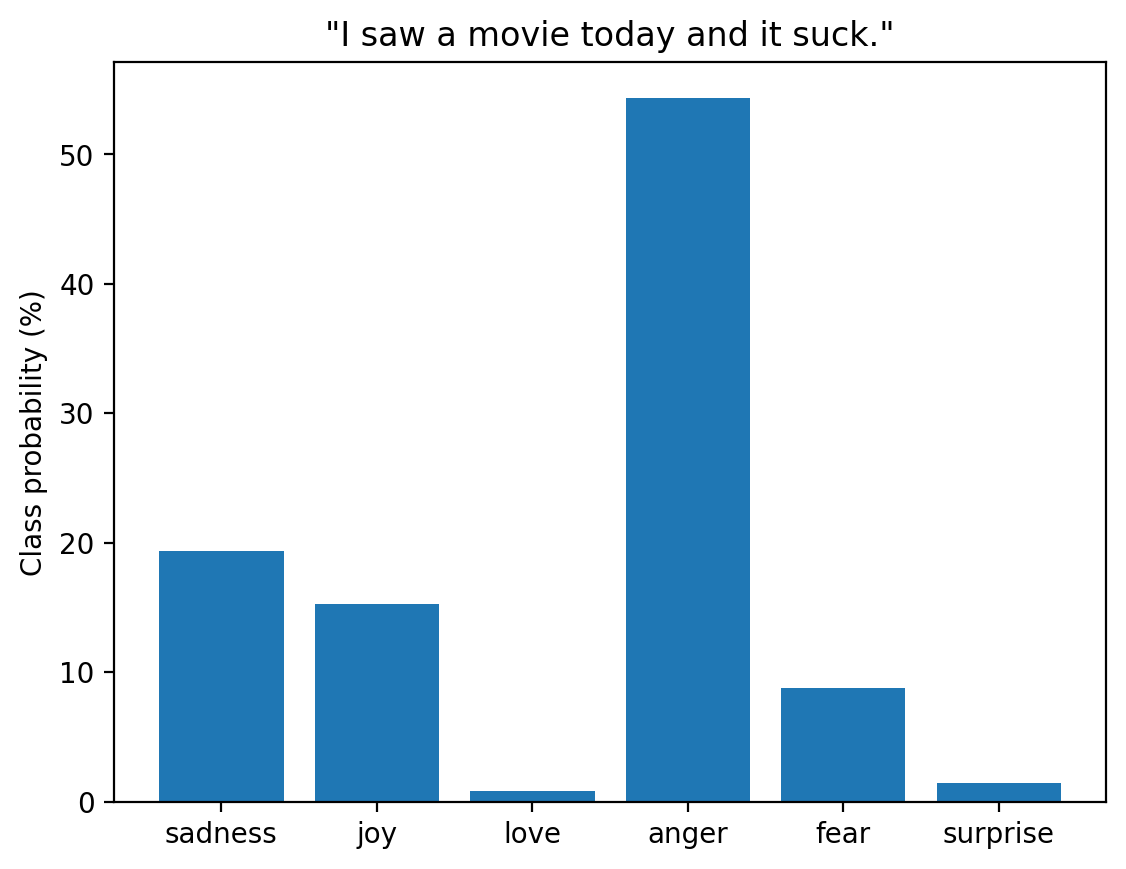

In [71]:
preds_df = pd.DataFrame(preds[0])
plt.bar(labels, 100 * preds_df["score"], color='C0')
plt.title(f'"{custom_tweet}"')
plt.ylabel("Class probability (%)")
plt.show()